In [2]:
!pip install -q kagglehub
import os, kagglehub
path = kagglehub.dataset_download("moltean/fruits")
print(path)

for root, dirs, files in os.walk(path):
    depth = root[len(path):].count(os.sep)
    if depth <= 3:
        print(root, "->", dirs[:5])


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
c:\Users\willi\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\willi\.cache\kagglehub\datasets\moltean\fruits\versions\107
C:\Users\willi\.cache\kagglehub\datasets\moltean\fruits\versions\107 -> ['fruits-360_100x100', 'fruits-360_3-body-problem', 'fruits-360_meta', 'fruits-360_multi', 'fruits-360_original-size']
C:\Users\willi\.cache\kagglehub\datasets\moltean\fruits\versions\107\fruits-360_100x100 -> ['fruits-360']
C:\Users\willi\.cache\kagglehub\datasets\moltean\fruits\versions\107\fruits-360_100x100\fruits-360 -> ['Test', 'Training']
C:\Users\willi\.cache\kagglehub\datasets\moltean\fruits\versions\107\fruits-360_100x100\fruits-360\Test -> ['Almonds 1', 'Apple 10', 'Apple 11', 'Apple 12', 'Apple 13']
C:\Users\willi\.cache\kagglehub\datasets\moltean\fruits\versions\107\fruits-360_100x100\fruits-360\Training -> ['Almonds 1', 'Apple 10', 'Apple 11', 'Apple 12', 'Apple 13']
C:\Users\willi\.cache\kagglehub\datasets\moltean\fruits\versions\107\fruits-360_3-body-problem -> ['fruits-360-3-body-problem']
C:\Users\willi\.cache\kagglehub\datasets\

In [3]:
DATA_DIR  = os.path.join(path, "fruits-360_100x100", "fruits-360")
TRAIN_DIR = os.path.join(DATA_DIR, "Training")
TEST_DIR  = os.path.join(DATA_DIR, "Test")

print(len(os.listdir(TRAIN_DIR)), "classes in Training")
print(len(os.listdir(TEST_DIR)), "classes in Test")

268 classes in Training
268 classes in Test


## Settings
Run cell ONCE, don't re-run it between experiments.

In [ ]:
import random

N_CLASSES = 40       # number of fruit classes to use (268 = all)
EPOCHS_HEAD = 3      # epochs with the pre-trained part frozen
EPOCHS_FINE = 3      # epochs while fine-tuning
SEED = 42

all_classes = sorted(os.listdir(TRAIN_DIR))
if N_CLASSES >= len(all_classes):
    chosen = all_classes
else:
    chosen = sorted(random.Random(SEED).sample(all_classes, N_CLASSES))

results = []         # experiment log 
os.makedirs("results", exist_ok=True)
print(len(chosen), "classes chosen")

40 classes chosen


## Load Data

In [8]:
!pip install tensorflow scikit-learn matplotlib seaborn
import tensorflow as tf
IMG = (224, 224); BS = 32
INPUT_SHAPE = IMG + (3,)
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="training", seed=42,
    image_size=IMG, batch_size=BS)
val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="validation", seed=42,
    image_size=IMG, batch_size=BS)
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG, batch_size=BS, shuffle=False)
class_names = train_ds.class_names


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Found 143177 files belonging to 268 classes.
Using 114542 files for training.
Found 143177 files belonging to 268 classes.
Using 28635 files for validation.
Found 47699 files belonging to 268 classes.


## Data Exploration

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# How many training images does each class have?
counts = pd.Series({c: len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in chosen})
print("Images per class (Training folder):")
print("  min :", counts.min(), "->", counts.idxmin())
print("  max :", counts.max(), "->", counts.idxmax())
print("  mean:", round(counts.mean(), 1))

Images per class (Training folder):
  min : 149 -> Cabbage red 1
  max : 738 -> Cherry Rainier 1
  mean: 514.4


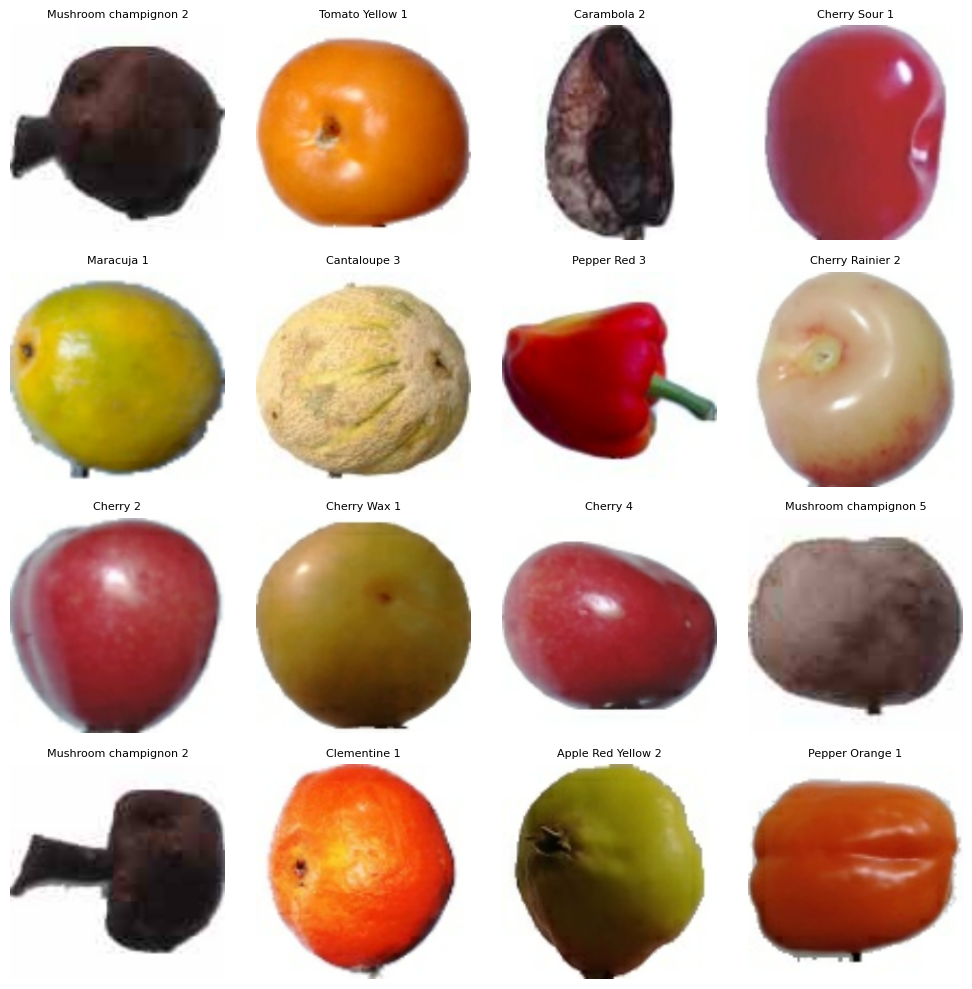

In [11]:
# Visualize some sample images from the training dataset
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(16):
        plt.subplot(4, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()], fontsize=8)
        plt.axis("off")
plt.tight_layout()
plt.savefig("results/sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

## Data Augmentation

In [9]:
from tensorflow.keras import layers

augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])